# Podstawy AI – Logika rozmyta: sterowniki

Plan:
1. Sterownik pralki – od dwóch reguł do pełnego sterownika
3. Sterownik wentylatora - plik fcl

**Jak pracujemy:**
- **TODO** w kodzie – tu piszesz kod lub zmieniasz liczby.
- **Testy** – komórka, którą uruchamiasz bez zmian. Wypisze `OK` albo `BŁĄD` z przypadkiem, który nie działa.
- **Pytanie** – odpowiadasz 2–3 zdaniami w komórce „Twoja odpowiedź”.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# ---- Gotowe funkcje z poprzednich zajęć ---------------------------------
def gamma(x, a, b):
    return np.clip((np.asarray(x, float) - a) / (b - a), 0, 1)

def L(x, a, b):
    return np.clip((b - np.asarray(x, float)) / (b - a), 0, 1)

def t(x, a, b, c):
    x = np.asarray(x, float)
    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0, 1)

def T_min(a, b):     return np.minimum(a, b)
def T_iloczyn(a, b): return np.asarray(a, float) * b
def T_luk(a, b):     return np.maximum(0, np.asarray(a, float) + b - 1)
def S_max(a, b):     return np.maximum(a, b)

def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6, equal_nan=True)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"BŁĄD  {nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"OK    {nazwa}" if bledy == 0 else f"      {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Sterownik pralki

Budujemy **sterownik**: program, który z reguł JEŚLI–TO wylicza czas prania. Działa w pięciu krokach:

| krok | co się dzieje |
|---|---|
| 1. rozmycie | liczby (np. 55%, 4 kg) zamieniamy na stopnie: „brud duży w stopniu 0,38” |
| 2. siła reguł | ile prawdy jest w części JEŚLI każdej reguły (t-norma) |
| 3. implikacja | zbiór wyjściowy przycinamy (min) albo skalujemy (iloczyn) siłą reguły |
| 4. łączenie | wnioski wszystkich reguł łączymy w jeden kształt (maksimum) |
| 5. wyostrzanie | z kształtu robimy jedną liczbę minut |

Zaczniemy od pralki z dwiema regułami, znajdziemy jej wady na **mapie sterownika** i zbudujemy pełną wersję.

### 2.1 Zbiory rozmyte pralki

Każda zmienna ma swoje zbiory, zapisane jako słownik `{nazwa: funkcja}`. Na start pralka zna tylko kilka z nich.

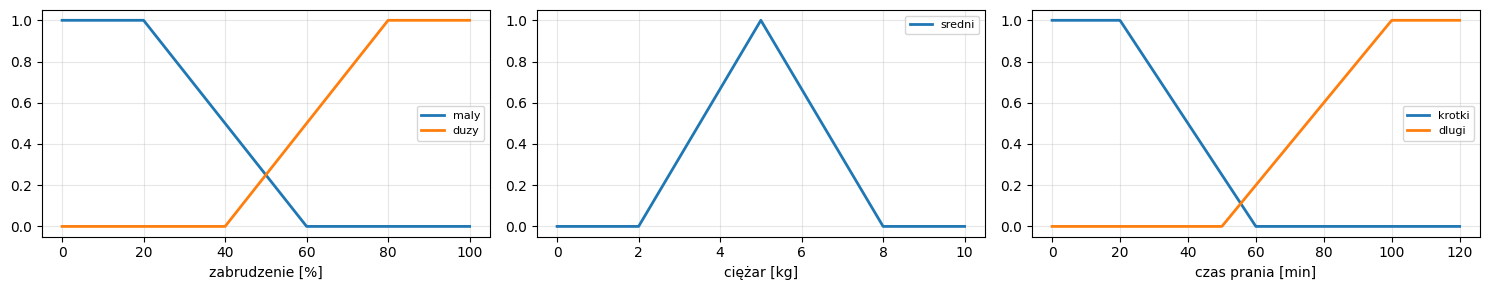

In [ ]:
BRUD = {                                   # zabrudzenie [%], 0–100
    "maly": lambda x: L(x, 20, 60),
    "duzy": lambda x: gamma(x, 40, 80),
}
CIEZAR = {                                 # ciężar prania [kg], 0–10
    "sredni": lambda x: t(x, 2, 5, 8),
}
CZAS = {                                   # czas prania [min], 0–120
    "krotki": lambda x: L(x, 20, 60),
    "dlugi":  lambda x: gamma(x, 50, 100),
}

def rysuj_zbiory(BRUD, CIEZAR, CZAS):
    fig, osie = plt.subplots(1, 3, figsize=(15, 3))
    for os_, (nazwa, zbiory, zakres) in zip(osie, [("zabrudzenie [%]", BRUD, 100),
                                                   ("ciężar [kg]", CIEZAR, 10),
                                                   ("czas prania [min]", CZAS, 120)]):
        xs = np.linspace(0, zakres, 501)
        for n, f in zbiory.items():
            os_.plot(xs, f(xs), lw=2, label=n)
        os_.set_xlabel(nazwa); os_.legend(fontsize=8); os_.grid(alpha=.3)
    plt.tight_layout(); plt.show()

rysuj_zbiory(BRUD, CIEZAR, CZAS)

**Pytanie 2a.** Spójrz na wykres ciężaru. Jaki stopień ma „średni” ciężar dla 1 kg i dla 9 kg? Co to może oznaczać dla pralki?

Dla 1kg i dla 9kg wykres wskazuje wartość 0, to wskazuje, że ten sterownik jest nieprawidłowy. Logicznie im cięższe pranie tym dłuższy czas aby je wyprać

### 2.2 Środek ciężkości

Ostatni krok, **wyostrzanie**, zamienia kształt na jedną liczbę. Kształt to dwie tablice: `x` – możliwe czasy prania, `mu` – wysokość kształtu nad każdym czasem. Środek ciężkości to średnia ważona czasów, a wagą jest `mu`:

$$x^* = \frac{x_1 \mu_1 + x_2 \mu_2 + \dots}{\mu_1 + \mu_2 + \dots}$$

Przykład: x = 0, 10, 20, 30 i mu = 0; 1; 0; 0,5 daje (10 · 1 + 30 · 0,5) / (1 + 0,5) = 25 / 1,5 ≈ 16,67.

Zaimplementuj tę funkcję. Jeśli wszystkie `mu` są zerami (żadna reguła nie zadziałała), zwróć `np.nan`.

In [ ]:
def srodek_ciezkosci(x, mu):
    x, mu = np.asarray(x, float), np.asarray(mu, float)
    # TODO
    suma_liczb_mu = np.sum(mu);
    if suma_liczb_mu == 0:
      return np.nan



    return np.sum(x*mu)/suma_liczb_mu

In [ ]:
# Testy
xs = np.array([0.0, 10.0, 20.0, 30.0])
sprawdz("srodek_ciezkosci", srodek_ciezkosci, [((xs, np.array([0, 1, 1, 0])), 15),
                                             ((xs, np.array([0, 0, 0, 1])), 30),
                                             ((xs, np.array([1, 0, 0, 1])), 15),
                                             ((xs, np.array([0, 1, 0, 0.5])), 50 / 3),
                                             ((xs, np.array([0, 0, 0, 0])), np.nan)])

OK    srodek_ciezkosci


### 2.3 Sterownik z dwiema regułami i mapa sterownika

Reguły zapisujemy jako słownik `{(brud, ciężar): czas}`. `None` znaczy „dowolny ciężar”:

- **R1:** JEŚLI brud **duży** I ciężar **średni**, TO czas **długi**
- **R2:** JEŚLI brud **mały**, TO czas **krótki**

Funkcja `sterownik` wykonuje pięć kroków dla dowolnego zestawu reguł. Nie musisz jej zmieniać – przeczytaj komentarze.

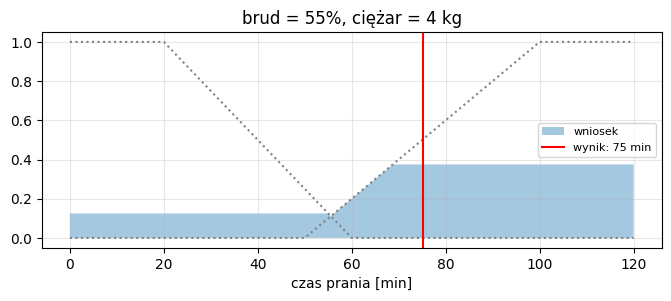

55%, 4 kg -> 75 min


In [ ]:
czas = np.linspace(0, 120, 1201)

def srodek_maksimum(x, mu):
    """Inna metoda wyostrzania: środek przedziału, w którym kształt jest najwyższy."""
    if np.max(mu) == 0:
        return np.nan
    return x[np.isclose(mu, np.max(mu))].mean()

def sterownik(brud, ciezar, reguly, T=T_min, implikacja="min", wyostrzanie=None, pokaz=False):
    wyostrzanie = wyostrzanie or srodek_ciezkosci
    # 1. rozmycie wejść
    st_brud = {n: float(f(brud)) for n, f in BRUD.items()}
    st_ciezar = {n: float(f(ciezar)) for n, f in CIEZAR.items()}
    wynik = np.zeros_like(czas)
    for (b, c), wyjscie in reguly.items():
        # 2. siła reguły (None = dowolny ciężar)
        sila = st_brud[b] if c is None else float(T(st_brud[b], st_ciezar[c]))
        # 3. implikacja: "min" przycina zbiór wyjściowy, "iloczyn" go skaluje
        zbior = CZAS[wyjscie](czas)
        wniosek = np.minimum(sila, zbior) if implikacja == "min" else sila * zbior
        # 4. łączenie wniosków
        wynik = S_max(wynik, wniosek)
    # 5. wyostrzanie
    x_star = wyostrzanie(czas, wynik)
    if pokaz:
        plt.figure(figsize=(8, 2.8))
        for n, f in CZAS.items():
            plt.plot(czas, f(czas), ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        if not np.isnan(x_star):
            plt.axvline(x_star, c="r", label=f"wynik: {x_star:.0f} min")
        plt.title(f"brud = {brud}%, ciężar = {ciezar} kg"); plt.xlabel("czas prania [min]")
        plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return x_star


REGULY_2 = {
    ("duzy", "sredni"): "dlugi",    # R1
    ("maly", None):     "krotki",   # R2
}

print(f"55%, 4 kg -> {sterownik(55, 4, REGULY_2, pokaz=True):.0f} min")

Sprawdzanie sterownika punkt po punkcie jest żmudne. **Mapa sterownika** liczy wynik dla wszystkich kombinacji zabrudzenia i ciężaru naraz. Białe pola to miejsca, gdzie **żadna reguła nie działa**.



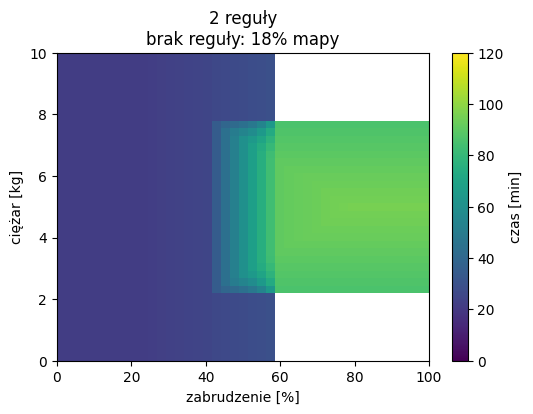

In [ ]:
def mapa(reguly, ax=None, tytul="", **ustawienia):
    brudy = np.linspace(0, 100, 41)
    ciezary = np.linspace(0, 10, 41)
    Z = np.array([[sterownik(b, c, reguly, **ustawienia) for b in brudy] for c in ciezary])
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    im = ax.imshow(Z, origin="lower", aspect="auto", extent=[0, 100, 0, 10], cmap="viridis", vmin=0, vmax=120)
    ax.set_xlabel("zabrudzenie [%]"); ax.set_ylabel("ciężar [kg]")
    ax.set_title(f"{tytul}\nbrak reguły: {np.isnan(Z).mean() * 100:.0f}% mapy")
    plt.colorbar(im, ax=ax, label="czas [min]")
    return Z

Z_2 = mapa(REGULY_2, tytul="2 reguły")
plt.show()

**Pytanie 2b.** Gdzie na mapie są białe pola? Opisz słowami, jakie to prania. Co zrobi prawdziwa pralka, gdy sterownik nie zwróci żadnej liczby?

**Pytanie 2c.** Na mapie widać prostokąt, w którym kolor zmienia się gwałtownie. Gdzie leży i skąd się bierze?

2b Białe pola są tam gdzie żadna z reguł nie działa.
Na mapie dla zabrudzenia > 60% i ciężaru > 8 kg, oraz dla zabrudzenia > 60% i ciężaru < 2 kg. Pralka albo się nie uruchomi no bo wykryje nan jak na poprzednim zadaniu albo skorzysta z wartosci domyślnych to już wg. osoby programującej.

2c. Na mapce leży: ciężar: 2kg ~ 8kg i zabrudzenie: 40% ~ 60%. Bierze się stąd że obydwie metody zaczynają się tam na siebie nakładać, wystarczy tam niewielka zmiana wartości ale wystarczy to do znaczącej zmiany wyniku tak jak widać na mapce

### 2.4 Pełna baza reguł

Zbuduj pralkę, która ma regułę na **każdą** sytuację: 3 stany zabrudzenia × 3 stany ciężaru = 9 reguł.

1. **Uzupełnij zbiory:** dodaj `"sredni"` do `BRUD`, `"lekki"` i `"ciezki"` do `CIEZAR` oraz `"sredni"` i `"bardzo_dlugi"` do `CZAS`. Możesz zmienić istniejące zbiory. Sąsiednie zbiory muszą się **nakładać**.
2. **Uzupełnij tabelę reguł:** w każdą komórkę słownika `REGULY_9` wpisz `"krotki"`, `"sredni"`, `"dlugi"` albo `"bardzo_dlugi"`.
3. Uruchom mapę i poprawiaj, aż białe pola znikną, a mapa będzie miała sens (więcej brudu i większy ciężar → dłużej).

In [ ]:
# TODO 1: uzupełnij zbiory (możesz też zmienić istniejące)
BRUD = {
        # TO DO
    "maly":   lambda x: L(x, 20, 60),
    "sredni":   lambda x: gamma(x, 40, 80),
    "duzy":   lambda x: gamma(x, 60, 100),
}
CIEZAR = {
    "lekki": lambda x: t(x, 1, 3, 6),
    "sredni": lambda x: t(x, 2, 5, 8),
    "ciezki": lambda x: t(x, 6, 9, 10),
    # TO DO
}
CZAS = {
    "krotki": lambda x: L(x, 20, 60),
    "sredni": lambda x: L(x, 40, 80),
    "dlugi":  lambda x: gamma(x, 50, 100),
    "bardzodlugi": lambda x: gamma(x, 90, 120),
    # TO DO
}

# TODO 2: uzupełnij tabelę reguł (zamień None na nazwę zbioru czasu)
REGULY_9 = {
    ("maly",   "lekki"):  "krotki",
    ("maly",   "sredni"): "krotki",
    ("maly",   "ciezki"): "sredni",
    ("sredni", "lekki"):  "sredni",
    ("sredni", "sredni"): "sredni",
    ("sredni", "ciezki"): "dlugi",
    ("duzy",   "lekki"):  "dlugi",
    ("duzy",   "sredni"): "dlugi",
    ("duzy",   "ciezki"): "bardzodlugi",
}


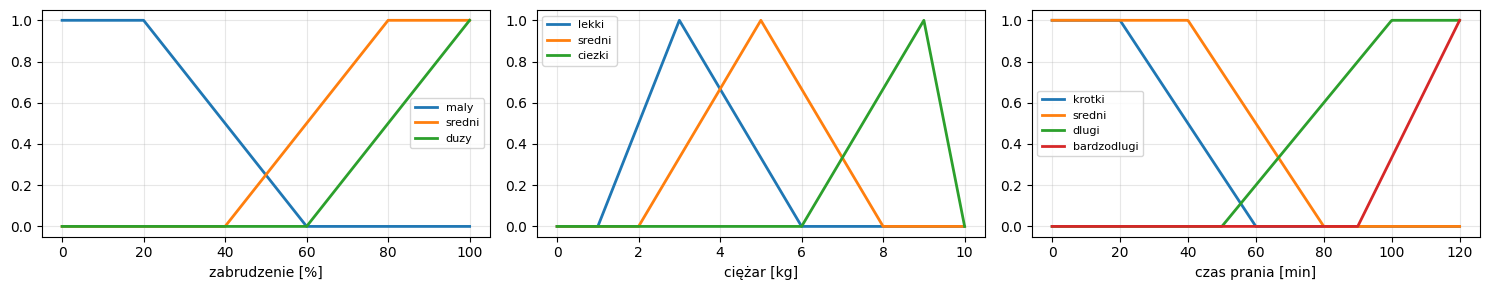

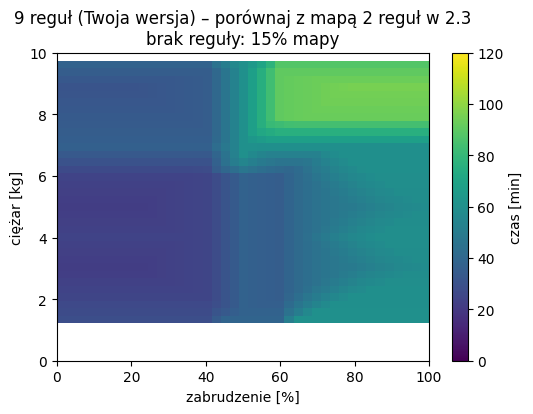

brud 10%, ciężar 1 kg -> nan min
brud 55%, ciężar 4 kg -> 36 min
brud 90%, ciężar 9 kg -> 95 min


In [ ]:
# Uruchamiaj po każdej zmianie
brakuje = [k for k, v in REGULY_9.items() if v is None or k[0] not in BRUD or k[1] not in CIEZAR or v not in CZAS]
if brakuje:
    print("Nie wszystko gotowe – sprawdź te reguły:", brakuje)
else:
    rysuj_zbiory(BRUD, CIEZAR, CZAS)
    Z_9 = mapa(REGULY_9, tytul="9 reguł (Twoja wersja) – porównaj z mapą 2 reguł w 2.3")
    plt.show()
    for b, c in [(10, 1), (55, 4), (90, 9)]:
        print(f"brud {b}%, ciężar {c} kg -> {sterownik(b, c, REGULY_9):.0f} min")

**Pytanie 2d.** Porównaj swoją mapę z mapą osoby obok. Wybierz jeden punkt (np. 70%, 3 kg), dla którego Wasze pralki dają najbardziej różne czasy. Kto ma rację – i jak można by to rozstrzygnąć?

**Pytanie 2e.** 2 wejścia po 3 stany to 9 reguł. Ile reguł trzeba by napisać dla 5 wejść po 3 stany? Co to mówi o ręcznym pisaniu reguł?

2d. mój wykres wskazując na 70% i 2kg daje czas ok. 60 min, natomiast w poprzednim zadaniu wychodził czas nan. Myślę, więc że mój wykres jest dokładniejszy

2e. 3^2 = 9 , 3^5 = 243. O ręcznym o pisaniu tych reguł mówi to tyle, że to bardzo żmudna i czasochłonna praca, lepiej ją zlecić maszynie.


### 2.5 Która decyzja projektowa ma największe znaczenie?

Ten sam sterownik ma trzy „pokrętła”: t-normę w części JEŚLI, implikację i metodę wyostrzania. Porównajmy, jak bardzo każde z nich zmienia całą mapę.

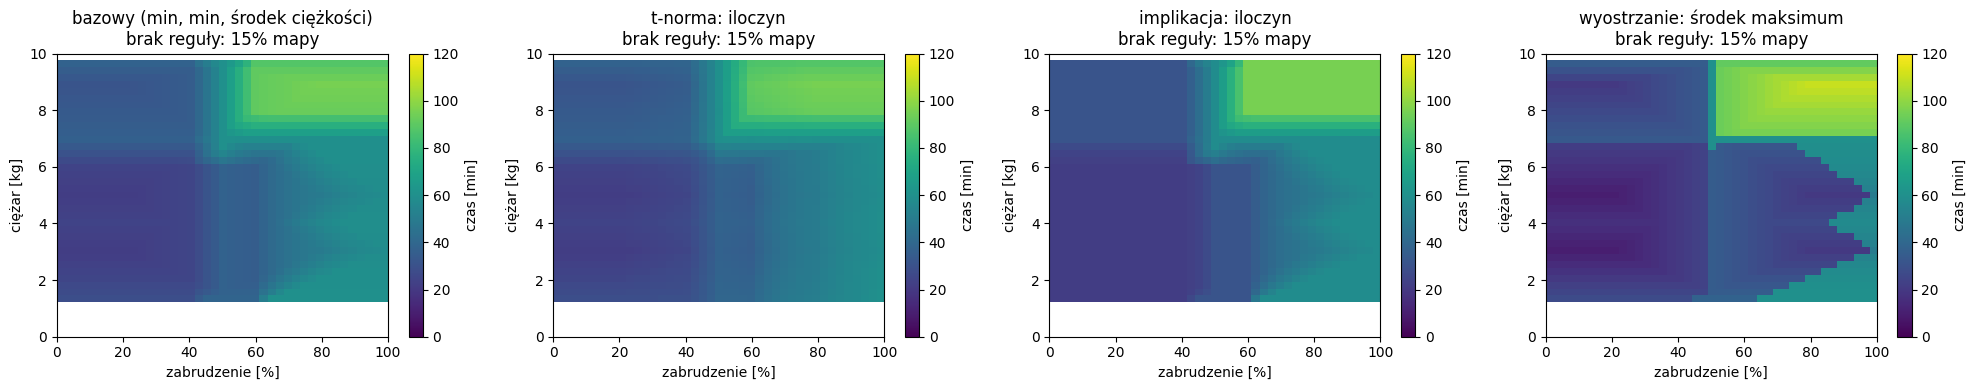

t-norma: iloczyn                 średnia różnica:  1.1 min, największa: 15.1 min
implikacja: iloczyn              średnia różnica:  2.9 min, największa:  8.8 min
wyostrzanie: środek maksimum     średnia różnica: 10.5 min, największa: 37.5 min


In [ ]:
warianty = {
    "bazowy (min, min, środek ciężkości)": {},
    "t-norma: iloczyn":                    {"T": T_iloczyn},
    "implikacja: iloczyn":                 {"implikacja": "iloczyn"},
    "wyostrzanie: środek maksimum":        {"wyostrzanie": srodek_maksimum},
}
if brakuje:
    print("Najpierw dokończ 2.4 – ta część używa Twojej pełnej bazy reguł.")
else:
    fig, osie = plt.subplots(1, 4, figsize=(20, 4))
    mapy = {n: mapa(REGULY_9, os_, n, **u) for os_, (n, u) in zip(osie, warianty.items())}
    plt.tight_layout(); plt.show()

    Z0 = mapy["bazowy (min, min, środek ciężkości)"]
    for n, Z in list(mapy.items())[1:]:
        d = np.abs(Z - Z0)
        print(f"{n:<32} średnia różnica: {np.nanmean(d):4.1f} min, największa: {np.nanmax(d):4.1f} min")

**Pytanie 2f.** Które pokrętło najbardziej zmienia sterownik? Która mapa ma wyraźne „schodki” (skoki koloru)?

Najbardziej zmienia sterownik pokrętło odpowiadające za metodę wyostrzania.
Najbardziej schodkową mapę ma wyostrzanie metodą środka maksimum. średnia różnica: 10.5 min, największa: 37.5 min

# Cześć 2: Sterownik wentylatora

## Cześć 2: język FCL i ocena sterownika

**FCL** (*Fuzzy Control Language*, norma IEC 61131-7) to standardowy, tekstowy format opisu sterowników rozmytych, używany w przemyśle. Plik FCL zawiera wszystko, co sterownik wie: zmienne, funkcje przynależności, reguły i ustawienia operatorów.

**Potrzebne pliki** (w tym samym folderze co notebook; w Google Colab: ikona folderu po lewej → „Prześlij”):
- `wentylator.fcl` – sterownik do analizy,
- `fcl_narzedzie.py` – narzędzie, które czyta pliki FCL i liczy wynik.

Nic nie trzeba instalować – narzędzie używa tylko `numpy` i `matplotlib`, które są w Colab.

**Plan:**
1. Analiza pliku FCL (A–C)
2. Dodanie stanu `very_hot` i nowej reguły
3. Testy sterownika
4. Trzy konfiguracje: implikacja, wyostrzanie, suma zbiorów
5. Ocena sterownika
6. Drugie wejście: wilgotność

**Do oddania:** pliki FCL (co najmniej 3 konfiguracje i wersja z wilgotnością) oraz ten notebook.

In [66]:
from fcl_narzedzie import wynik, tabela, rysuj_zbiory, krzywa, wariant, rozszerz, krzywe
print(open("wentylator.fcl", encoding="utf-8").read())

(* Podstawy AI – sterownik rozmyty wentylatora
   Jedno wejście: temperatura, jedno wyjście: prędkość wentylatora. *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skalu

---
## 1. Analiza pliku FCL

Plik składa się z bloków. Każdy odpowiada jednemu krokowi sterownika rozmytego:

| blok | co zawiera |
|---|---|
| `VAR_INPUT` / `VAR_OUTPUT` | nazwy wejść i wyjść |
| `FUZZIFY` | funkcje przynależności wejścia, zapisane punktami `(x, μ)` – łamana przez te punkty |
| `DEFUZZIFY` | funkcje przynależności wyjścia, metoda wyostrzania `METHOD`, wartość `DEFAULT` |
| `RULEBLOCK` | operatory (`AND`, `ACT` – implikacja, `ACCU` – suma zbiorów) i reguły `IF … THEN …` |

Przykład: `TERM cold := (0, 1) (10, 1) (20, 0);` znaczy: do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C.

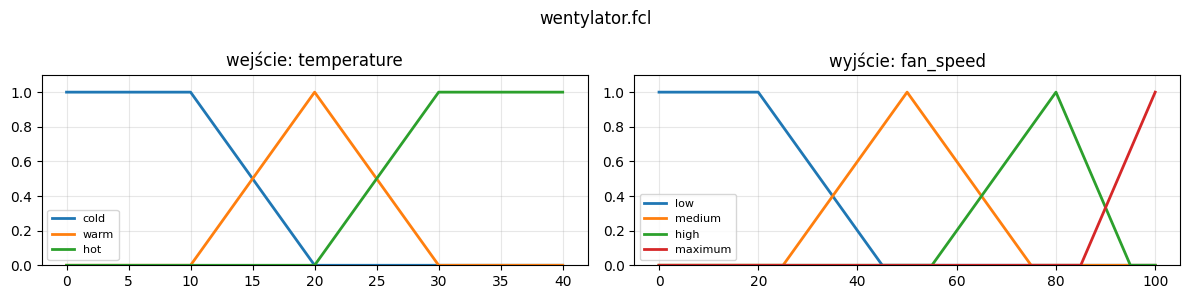

In [67]:
rysuj_zbiory("wentylator.fcl")

**Zadanie 1A.** Wypisz zmienne wejściowe i wyjściowe (nazwa, zakres, jednostka).

**Zadanie 1B.** Wypisz funkcje przynależności każdej zmiennej i opisz słowami, co znaczą (np. „cold – do 10 °C na pewno zimno, od 20 °C na pewno nie”).

**Zadanie 1C.** Wypisz reguły i opisz jednym zdaniem, jak działa ten sterownik.

1A. Wejściem jest temperatura zakres: 0-40 stopni C jednostka: stopnie C
Wyjście to prędkość wiatraka zakres 0 - 100 %

1B. Temperatura :
cold : 0-20
warm : 10 - 30
hot : 20 - 40

Prędkość :
low : 0-43
medium : 24-76
high : 56-90
maximum :83-100

temperatura zimno -> wiatrak low
temperatura warm -> wiatrak medium
temperatura hot -> wiatrak high
temperatura hot (max)  -> wiatrak maximum

W skrócie im wyższa temperatura tym wyższa prędkość wiatraka.

---
## 2. Dodanie stanu `very_hot`

Komórka poniżej zapisuje plik `wentylator_k1.fcl`. Na start zawiera kopię oryginału. Zmień go bezpośrednio w komórce:

1. **(A)** Dodaj do `temperature` stan `very_hot`. Pamiętaj, że `hot` i `very_hot` muszą się **nakładać**, a `hot` powinien przestać być płaski do 40 °C (inaczej przy 40 °C będzie jednocześnie w pełni „hot” i „very_hot”).
2. **(B)** Dodaj regułę: jeśli `very_hot`, to `fan_speed` = `maximum`.

Uruchom komórkę – zapisze plik. Potem uruchom następną, żeby zobaczyć wykres.

In [68]:
%%writefile wentylator_k1.fcl
 (* Podstawy AI – wentylator z dodanym stanem very_hot (konfiguracja 1: MIN / MAX / COG) *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (28, 1) (36, 0);
    TERM very_hot := (30, 0) (36, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skaluje *)
    ACCU : MAX;             (* suma zbiorów na wyjściu: MAX, BSUM *)

    RULE 1 : IF temperature IS cold THEN fan_speed IS low;
    RULE 2 : IF temperature IS warm THEN fan_speed IS medium;
    RULE 3 : IF temperature IS hot  THEN fan_speed IS high;
    RULE 4 : IF temperature IS very_hot THEN fan_speed IS maximum;
END_RULEBLOCK

END_FUNCTION_BLOCK

Writing wentylator_k1.fcl


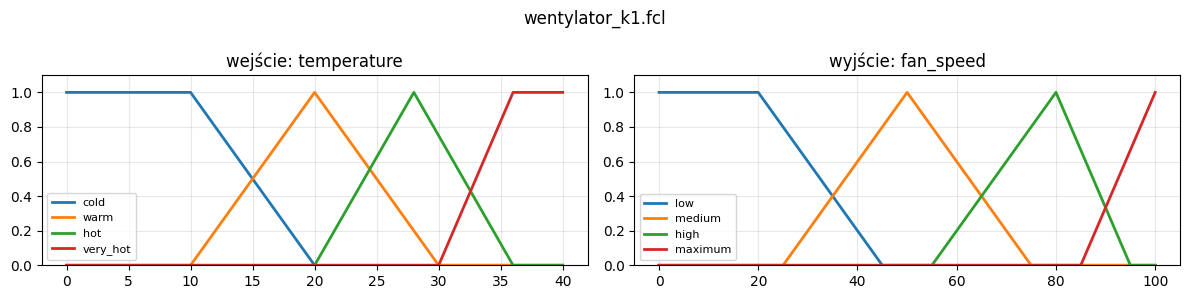

In [ ]:
rysuj_zbiory("wentylator_k1.fcl")

---
## 3. Testy sterownika

**Zadanie 2C.** Porównaj oryginał i Twoją wersję dla temperatur od 0 do 40 °C co 5 stopni. Wykres pokazuje prędkość dla wszystkich temperatur naraz.

 temperature  wentylator  wentylator_k1
           0       17.03          17.03
           5       17.03          17.03
          10       17.03          17.03
          15       34.44          34.44
          20       50.00          50.00
          25       61.15          62.29
          30       76.67          76.50
          35       76.67          87.01
          40       76.67          95.03


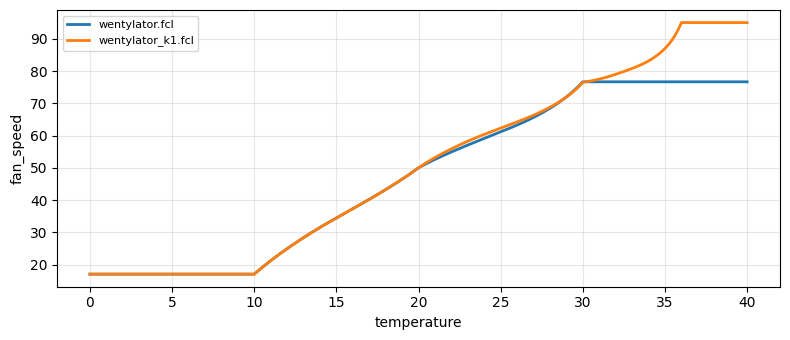

In [69]:
TEMPERATURY = [0, 5, 10, 15, 20, 25, 30, 35, 40]
tabela(["wentylator.fcl", "wentylator_k1.fcl"], "temperature", TEMPERATURY)
krzywa(["wentylator.fcl", "wentylator_k1.fcl"], "temperature")

**Pytanie 3a.** Co robi oryginalny sterownik powyżej 30 °C? Co zmieniło dodanie `very_hot`?

**Pytanie 3b.** Jaką prędkość daje sterownik przy 0 °C, a jaką przy 40 °C? Czy wentylator kiedykolwiek się wyłącza albo osiąga 100%? Dlaczego?

3a. oryginał powyżej 30 stopni się wypłaszcza, nie powinno tak być. Dzięki dodaniu stanu very hot prędkość nadal wzrasta po przekroczeniu 30 stopni.

3b. Przy 0 wentylator wg. wykresu ma bardzo male obroty ale się nie wyłącza. przy 40 stopniach osiąga ponad 90% ale nie wiemy czy dobija 100%.

---
## 4. Trzy konfiguracje

**Zadanie 3A.** Przetestuj sterownik z innymi ustawieniami. Każda konfiguracja to osobny plik FCL, w którym zmieniasz **jedną** rzecz:

| ustawienie w FCL | co określa | wariant do sprawdzenia |
|---|---|---|
| `ACT` | implikacja: jak siła reguły zmienia jej wniosek | `PROD` zamiast `MIN` |
| `METHOD` | wyostrzanie: jak z kształtu zrobić jedną liczbę | `MM` (środek maksimum) zamiast `COG` |
| `ACCU` | suma zbiorów na wyjściu: jak łączyć wnioski reguł | `BSUM` (suma ograniczona) zamiast `MAX` |

Funkcja `wariant` tworzy kopię pliku ze zmienionym ustawieniem. Możesz też skopiować plik ręcznie i zmienić jedną linijkę.

Zapisano wentylator_k2.fcl: ACT = PROD
Zapisano wentylator_k3.fcl: METHOD = MM
Zapisano wentylator_k4.fcl: ACCU = BSUM
 temperature  wentylator_k1  wentylator_k2  wentylator_k3  wentylator_k4
           0          17.03          17.03          10.00          17.03
           5          17.03          17.03          10.00          17.03
          10          17.03          17.03          10.00          17.03
          15          34.44          31.08          30.93          34.50
          20          50.00          50.00          50.00          50.00
          25          62.29          63.21          78.15          62.59
          30          76.50          76.67          78.75          76.50
          35          87.01          89.86          98.75          87.27
          40          95.03          95.03         100.00          95.03
          28          68.78          71.82          80.00          68.39
          32          78.99          79.80          77.50          79.95
     

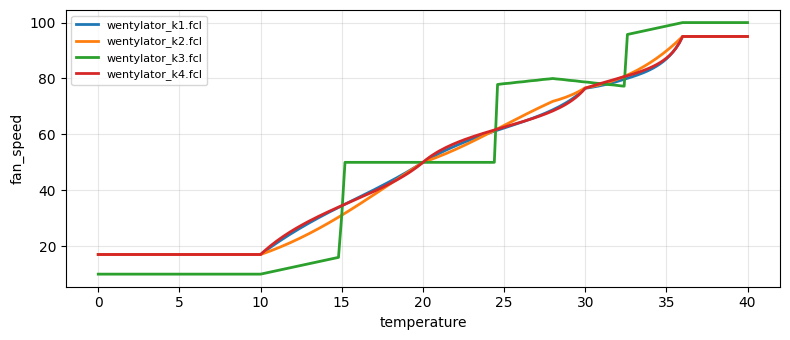

In [70]:
k2 = wariant("wentylator_k1.fcl", "wentylator_k2.fcl", ACT="PROD")
k3 = wariant("wentylator_k1.fcl", "wentylator_k3.fcl", METHOD="MM")
k4 = wariant("wentylator_k1.fcl", "wentylator_k4.fcl", ACCU="BSUM")

KONFIGURACJE = ["wentylator_k1.fcl", k2, k3, k4]
tabela(KONFIGURACJE, "temperature", TEMPERATURY + [28, 32, 34])
krzywa(KONFIGURACJE, "temperature")

**Zadanie 3A (opis).** Dla każdej konfiguracji opisz: co zmieniłeś, przy jakich temperaturach wynik się zmienił i o ile. Która zmiana ma największy wpływ?

3a. Zmiana k3 powoduje najbardziej skokowe działanie
0-10C wynik około 10 zamiast 17,
dla 15C spada do około 30,9,
dla 25C rośnie do około 78,1 zamiast 62,3


## 5. Ocena sterownika

**Zadanie 3B.** Jak oceniasz działanie sterownika? Odnieś się do:
- czy prędkość rośnie z temperaturą płynnie, czy skokami,
- czy zakres prędkości (najmniejsza i największa) jest sensowny dla wentylatora,
- którą konfigurację wybrałbyś do prawdziwego urządzenia i dlaczego.

---
## 6. Drugie wejście: wilgotność

Przy wysokiej wilgotności to samo ciepło jest bardziej uciążliwe, więc wentylator powinien kręcić się szybciej. Dodajemy do Twojego sterownika z części 2 drugie wejście `humidity` (wilgotność powietrza, 0–100%).

### 6.1 Rozszerzenie pliku

Nie musisz przepisywać całego pliku. Funkcja `rozszerz` bierze `wentylator_k1.fcl` i wkleja we właściwe miejsca trzy fragmenty, które piszesz w FCL:
1. nowe wejście w `VAR_INPUT` (gotowe),
2. blok `FUZZIFY humidity` z trzema stanami: `dry`, `normal`, `humid`,
3. co najmniej dwie nowe reguły, np. „ciepło **i** wilgotno → szybko”, „gorąco **i** wilgotno → maksimum”.

Zapisano wentylator_h.fcl – plik wczytuje się poprawnie.


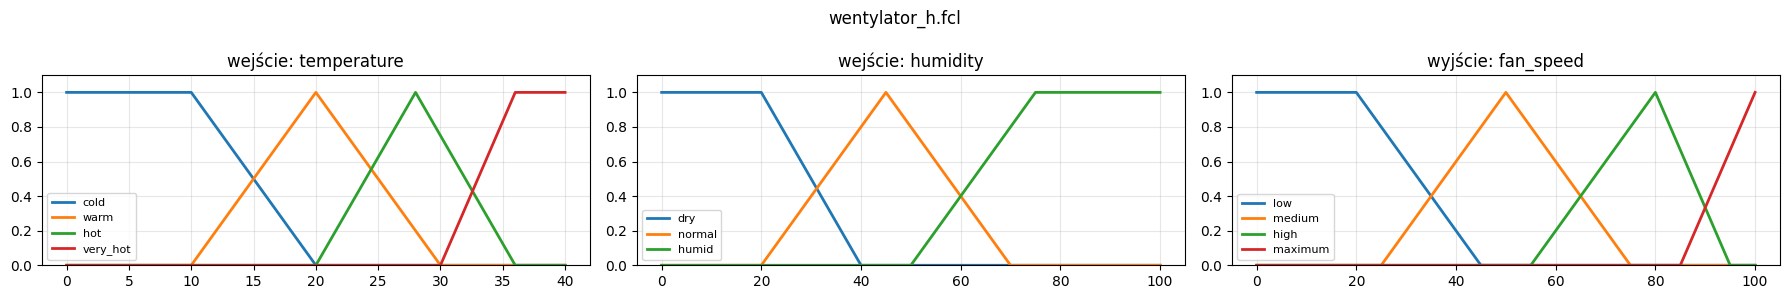

In [71]:
NOWE_WEJSCIE = "humidity : REAL;     (* wilgotność [%] *)"

NOWY_FUZZIFY = """
FUZZIFY humidity
    RANGE := (0 .. 100);
    TERM dry    := (0, 1) (20, 1) (40, 0);
    TERM normal := (20, 0) (45, 1) (70, 0);
    TERM humid  := (50, 0) (75, 1) (100, 1);
END_FUZZIFY
"""

NOWE_REGULY = """
RULE 5 : IF temperature IS warm AND humidity IS humid THEN fan_speed IS high;
RULE 6 : IF temperature IS hot AND humidity IS humid THEN fan_speed IS maximum;
"""

rozszerz("wentylator_k1.fcl", "wentylator_h.fcl",
         wejscie=NOWE_WEJSCIE, fuzzify=NOWY_FUZZIFY, reguly=NOWE_REGULY)
rysuj_zbiory("wentylator_h.fcl")

Powietrze suche (humidity = 20):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         34.44
          20         50.00
          25         62.29
          30         76.50
          35         87.01
          40         95.03

Powietrze wilgotne (humidity = 90):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         45.58
          20         61.54
          25         66.71
          30         80.92
          35         87.01
          40         95.03

Stała temperatura 25 °C:
    humidity  wentylator_h
           0         62.29
          20         62.29
          40         62.29
          60         65.31
          75         66.71
          90         66.71
         100         66.71


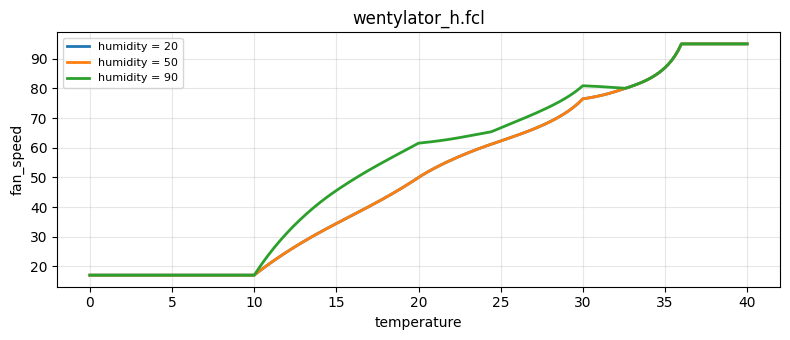

In [ ]:
print("Powietrze suche (humidity = 20):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=20)
print("\nPowietrze wilgotne (humidity = 90):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=90)
print("\nStała temperatura 25 °C:")
tabela("wentylator_h.fcl", "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6a.** O ile wilgotne powietrze zwiększa prędkość przy 25 °C? Czy to dużo, czy mało?

**Pytanie 6b.** Czy wilgotność cokolwiek zmienia przy 10 °C? Dlaczego?

**Pytanie 6c.** Reguła 2 („warm → medium”) nic nie wie o wilgotności. Co robi, gdy powietrze jest wilgotne? Jak to wpływa na wynik z pytania 6a?

6a. przy 25 stopniach i wilgotnosci 50 prędkość wzrasta z 62% na  66% przy wilgotnosci 90 . To nie dużo.
6b. przy 10 stopniach wilgotność nic nie zmienia, i tak jest zimno więc nie ma sensu zwiekszac predkosci

6c. Reguła 2 („warm → medium”) działa tak samo jak bez wilgotności bo nie uwzględnia tego wskaźnika